# Project in Signals and transforms --- Lab 1 simulation

In [108]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

import wcslib as wcs

## Parameters
Parameters of the system. Update the parameters according to your choices.

In [109]:
# TODO: Add your parameters here.

# General parameters
channel_id = 7    # Your channel number
dt = 1/22050

# Baseband signal parameters
Tb = 1 / 50            # Symbol width in seconds

# Carrier signal parameters
Ac = 1                              # Carrier signal ampltiude
wc = (2300 + 2100) / 2 * 2 * np.pi  # Carrier signal frequency

# Test message
data = "Hello world!"

## Transmitter

In [110]:
# Convert string to bit sequence
bs = wcs.encode_string(data)
    
# Encode baseband signal
xb = wcs.encode_baseband_signal(bs, Tb, 0.5, 1)

# TODO: Implement modulation using the carrier signal here. Plot both the baseband signal and the modulated signal.

t = np.arange(len(xb)) * dt

xc = Ac * np.sin(wc * t)
xm = xb * xc

## Simulate transmission

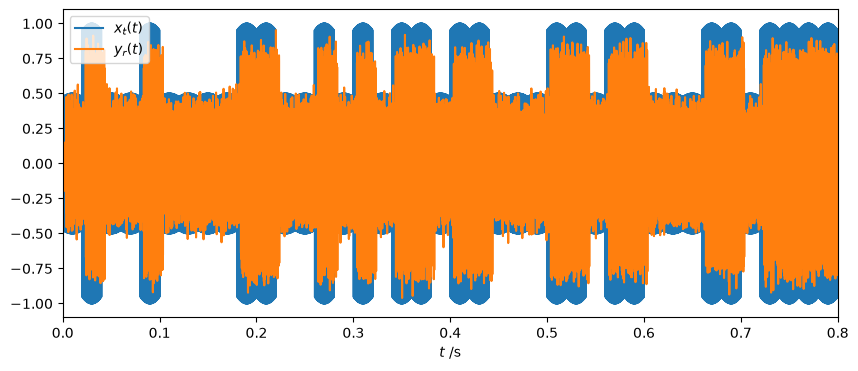

In [111]:
xt = xm
yr = wcs.simulate_channel(xt, channel_id=channel_id)

# TODO: Plot the received signal.

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_xlabel('$t$ /s')

ax.set_xlim(0, 5 * 8 * Tb)

t_r = np.arange(len(yr)) * dt

ax.plot(t, xt, label="$x_t(t)$")
ax.plot(t_r, yr, label="$y_r(t)$")
ax.legend()

## Receiver

Received: Hello world!


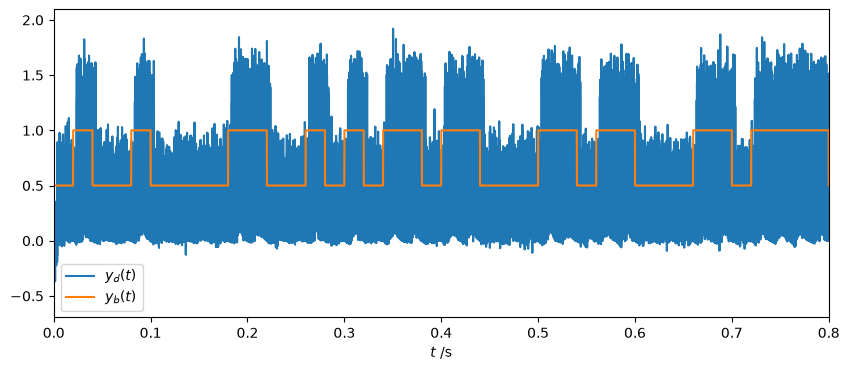

In [112]:
# TODO: Put your receiver code (demodulation, etc.) here. Plot all relevant signals.

t_d = np.arange(len(yr)) * dt

yd = 2 * yr * np.sin(wc * t_d)
yb = Ac * xb

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_xlabel('$t$ /s')

ax.set_xlim(0, 5 * 8 * Tb)

t_yb = np.arange(len(yb)) * dt

ax.plot(t_d, yd, label="$y_d(t)$")
ax.plot(t_yb, yb, label="$y_b(t)$")
ax.legend()

# Symbol and string decoding
br = wcs.decode_ask_baseband_signal(yb, Tb)
data_rx = wcs.decode_string(br)
print('Received: ' + data_rx)

## Task 4

### c)

Text(0.5, 0, '$\\omega$ / rad/s')

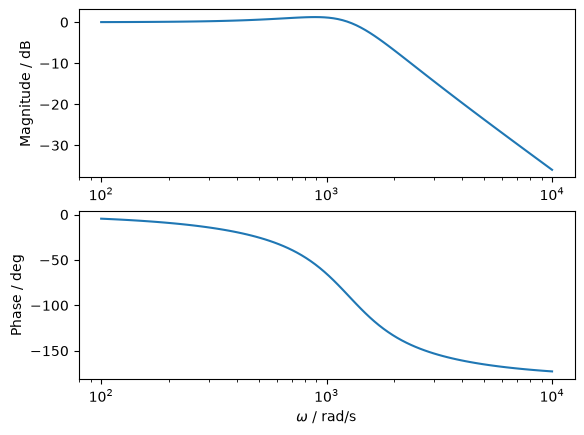

In [113]:
alpha = 2 * np.pi * 200

# Generate transfer function
num = [alpha ** 2]
den = [1, alpha, alpha ** 2]
H = signal.TransferFunction(num, den) # Low-pass filter

# Plot bode diagram
w, mag, phase = H.bode()
fig, ax = plt.subplots(2, 1)
ax[0].semilogx(w, mag)
ax[0].set_ylabel('Magnitude / dB')

ax[1].semilogx(w, phase)
ax[1].set_ylabel('Phase / deg')
ax[1].set_xlabel(r'$\omega$ / rad/s')

### d)

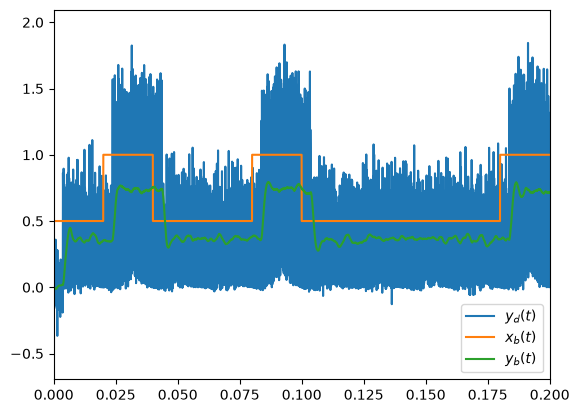

In [114]:
t = np.arange(len(yd)) * dt

t_yb, yb, _ = signal.lsim(H, yd, t)

fig, ax = plt.subplots()

ax.set_xlim(0, 10 * Tb)

t_xb = np.arange(len(xb)) * dt

ax.plot(t, yd, label="$y_d(t)$")
ax.plot(t_xb, xb, label="$x_b(t)$")
ax.plot(t_yb, yb, label="$y_b(t)$")
ax.legend()

### e)

In [115]:
decoded_signal = wcs.decode_ask_baseband_signal(yb, Tb)
result_string = wcs.decode_string(decoded_signal)
print(result_string)

Hello world!
